# Лекция 7. Производные: конечные разности и алгоритмическое дифференцирование

**Курс:** Вычислительная оптимизация · **Часть II. Безусловная оптимизация и ньютоновские методы** · Лекция 7 из 16 · 21 октября 2026

**Материалы:** [конспект-ноутбук с кодом демонстраций](lecture07.ipynb) · [демо-ноутбук](demo07.ipynb) · [разбор упражнений](exercises07.ipynb)

В конспекте-ноутбуке три демонстрации стоят прямо в тексте: «Демо (a)» — конечные разности — после раздела 2, «Демо (b)» — прямой и обратный режим своими руками — после раздела 4, «Демо (c)» — CasADi на цепи — после раздела 5. Задачи введения и подробности — только в `demo07.ipynb` (части (0) и (e)).

---

> **Код в этом ноутбуке.** Три демонстрации из [`demo07.ipynb`](demo07.ipynb) вставлены в те разделы, к которым относятся: «Демо (a)» — конечные разности — после раздела 2, «Демо (b)» — прямой и обратный режим своими руками — после раздела 4, «Демо (c)» — CasADi на цепи — после раздела 5; числа введения и подробности — только в `demo07.ipynb`. Вспомогательный код (палитра, разности, мини-АД `forward_mode` / `reverse_mode`, цепь) вынесен в [`l7helpers.py`](l7helpers.py); его подключает ячейка ниже. Нужен CasADi: `uv run --group casadi jupyter lab`, в Colab он ставится сам.

In [1]:
%matplotlib inline

from l7helpers import *  # палитра, разности, мини-АД, цепь (см. файл рядом)

## Сколько стоит градиент

В ДЗ 3 вы писали якобиан синуса руками: три столбца, и у половины группы в одном из них была ошибка в знаке. В ДЗ 4 вам дан гессиан упругой цепи: $80\times80$, на каждую пружину — блок $2\times2$ с $\dfrac{DL}{d^3}$ внутри; формулы на страницу. Одна опечатка — и Ньютон идёт не туда, а узнаете вы об этом по странной картинке через час.

Можно не писать производные вовсе и брать разности: $\partial_if\approx\dfrac{f(x+he_i)-f(x)}{h}$. Цена на цепи с $n=80$ переменными — $81$ вычисление энергии на градиент; гессиан разностями по энергии — $25\,600$ вычислений, и ошибка в нём $3\cdot10^{-5}$. Точность градиента — восемь знаков из шестнадцати.

А можно отдать программу, которая считает энергию, инструменту CasADi. Он вернёт градиент ценой **$1.6$ вычисления энергии** — не $81$, а полтора, — и точный до последнего бита; гессиан — за $5.5$ вычислений, с готовой разреженностью. При $n=2000$ числа те же: $1.6$ и $5.7$. Цена точного градиента **не зависит от числа переменных**.

Это не фокус CasADi, а алгоритм, которому тридцать лет. На нём же стоит обучение нейросетей: у GPT-3 $175$ миллиардов параметров, градиент разностями стоил бы $175$ миллиардов прогонов сети, а обратный проход (*backpropagation*) — примерно два прогона. Сегодня вы увидите этот алгоритм на функции из трёх операций и посчитаете его руками.

<img src="img/00_hooks.png" width="900" alt="три факта введения: слева U-кривая ошибки прямой разности с минимумом 1.4e−6 при h = 6e−9; в центре цена градиента в ценах f против числа переменных n — разности растут как n + 1 до 1.75e11 у GPT-3, обратный режим держится на 1.6; справа портрет гессиана упругой цепи 80×80 — четыре ленты, 7 % ненулевых">

*Три факта лекции. Слева: ошибка прямой разности по шагу $h$ — буква U с дном $10^{-6}$. В центре: цена градиента в ценах $f$ — разности растут с $n$, обратный режим — нет, и для GPT-3 это разница между $1.75\cdot10^{11}$ и $2$. Справа: гессиан упругой цепи — четыре ленты, $7\,\%$ ненулевых, и CasADi знает это до вычислений.*

**Зачем это вам.** Все методы части II требуют $\nabla f$, Ньютон — ещё и $\nabla^2f$, Гаусс–Ньютон — якобиан. Пока $f$ была формулой в две строки, производные писались руками. Когда $f$ — программа на сто строк (модель, симулятор, нейросеть), остаются два пути: разности или алгоритмическое дифференцирование. Лекция о том, чего стоит каждый.

**Три вопроса лекции:**

1. Насколько точна конечная разность и какой шаг $h$ брать?
2. Как получить точный градиент за две-три цены $f$ при любом $n$?
3. Что CasADi делает за нас — и чего не делает?

## 1. Повторение: кому какие производные нужны

### 1.1. Четыре лекции на одной странице

| Лекция | Метод | Какие производные нужны | Число, которое стоит помнить |
|---|---|---|---|
| 4 | градиентный спуск | $\nabla f$ | Розенброк: $13\,756$ итераций при $\kappa=2508$ |
| 5 | Ньютон, BFGS, Гаусс–Ньютон | $\nabla f$ и $\nabla^2f$; BFGS — только $\nabla f$; Гаусс–Ньютон — якобиан $J$ | Ньютон $7$, BFGS $34$ |
| 6 | линейный поиск, доверительная область | те же плюс $f$ на пробных точках | доверительная область: $25$ итераций, $3$ отвергнуты |
| 4, 6 (семинары) | CasADi: `gradient`, `hessian`, `nlpsol` | строит сам — как, узнаем сегодня | IPOPT с точным гессианом |

### 1.2. Одна формула и что в ней производные

$$
\boxed{\;x_{k+1}=x_k-\alpha_k\,B_k^{-1}\nabla f(x_k)\;}
$$

Всё, что здесь стоит, кроме длины шага $\alpha_k$, — производные: градиент $\nabla f(x_k)$ и матрица кривизны $B_k$ (гессиан, его замена из секущего уравнения или $J^\top J$). Чем точнее они, тем точнее ответ. Вот что бывает, когда градиент взят разностями:

<img src="img/01_review.png" width="900" alt="повторение: слева пути BFGS на Розенброке из (−1.2, 1) с точным градиентом и с разностным — пути совпадают, 33 итерации у обоих; справа норма точного градиента по итерациям: с точным градиентом она уходит к 2.6e−8, с разностным останавливается на 6e−6, пунктир — допуск gtol = 1e−6">

*BFGS из лекции 5 на Розенброке (`scipy.optimize.minimize`, `method="BFGS"`, `gtol=1e-6`): с точным градиентом и с градиентом, который SciPy взял разностями сам (`jac=None`). Пути совпадают, итераций у обоих $33$. Но функция вызвана $120$ раз вместо $40$, а ответ отстоит от $(1,1)$ на $10^{-5}$ вместо $10^{-9}$: разностный градиент ошибается на $\sim10^{-5}$, и солвер остановился, поверив ему.*

### 1.3. Блиц: пять вопросов

1. Почему спуск на Розенброке делает $13\,756$ итераций?
2. Когда шаг Ньютона ведёт *вверх* по функции?
3. Что измеряет секущее уравнение $B_{k+1}s_k=y_k$?
4. Что Гаусс–Ньютон отбрасывает от гессиана?
5. Что такое $\rho_k$ в доверительной области и что бывает при $\rho_k<0$?

<details>
<summary>Ответы</summary>

1. Число обусловленности гессиана у решения $\kappa=2508$: зигзаг поперёк долины, итераций $\sim\kappa\ln(1/\varepsilon_{\text{tol}})$ (Л4, §5).
2. Когда гессиан индефинитен (есть собственные числа обоих знаков): модель — седло, шаг идёт в её стационарную точку (Л5, §3.4).
3. Кривизну функции вдоль сделанного шага — по разности градиентов, без вторых производных (Л5, §4.2).
4. Член $\sum_ir_i\nabla^2r_i$ — вторые производные невязок; у решения с малыми невязками он мал (Л5, §5.2).
5. Отношение фактического уменьшения $f$ к обещанному моделью; при $\rho_k<0$ функция выросла, шаг отвергнут, радиус вчетверо меньше (Л6, §3.2).

</details>

### 1.4. Что сегодня

Конечные разности: две ошибки, U-кривая и цена (раздел 2) → программа как список операций, прямой режим: производная по направлению за одну цену $f$ (3) → обратный режим: весь градиент за один проход (4) → CasADi: граф операций, разреженность, что он не умеет (5) → что передавать солверу (6).

## 2. Конечные разности: две ошибки и одна U

**Главная мысль.** Разность значений приближает производную с двумя ошибками: усечения (формула неточна, растёт с $h$) и округления (вычитаются близкие числа, растёт при малых $h$). Их сумма имеет минимум при $h\sim\sqrt\varepsilon$, и лучшая точность прямой разности — около $10^{-8}$, половина знаков числа.

### 2.1. Прямая разность и откуда берётся $\sqrt\varepsilon$

По формуле Тейлора $f(x+h)=f(x)+hf'(x)+\tfrac{h^2}{2}f''(x)+\dots$, поэтому

$$
\frac{f(x+h)-f(x)}{h}=f'(x)+\underbrace{\tfrac h2f''(x)+\dots}_{\text{ошибка усечения}} .
$$

Это была бы вся история, если бы $f$ считалась точно. Но компьютер хранит число с **машинной точностью** $\varepsilon\approx2.2\cdot10^{-16}$: это относительная ошибка одного числа, $16$ десятичных знаков. Каждое из двух значений $f$ известно с ошибкой до $\varepsilon\lvert f\rvert$; при вычитании близких чисел ошибки не сокращаются, а деление на малое $h$ их увеличивает:

$$
\text{ошибка округления}\approx\frac{2\varepsilon\lvert f\rvert}{h},\qquad
\text{ошибка всего}\approx\frac h2\lvert f''\rvert+\frac{2\varepsilon\lvert f\rvert}{h}.
$$

Первое слагаемое растёт с $h$, второе убывает; минимум суммы — там, где они равны:

$$
h^\ast=2\sqrt{\frac{\varepsilon\lvert f\rvert}{\lvert f''\rvert}}\sim\sqrt\varepsilon\approx1.5\cdot10^{-8},\qquad
\text{ошибка}\approx2\sqrt{\varepsilon\lvert f\rvert\lvert f''\rvert}\sim\sqrt\varepsilon .
$$

Для $\partial f/\partial x_1$ Розенброка в $(-1.2,1)$ — $f=24.2$, $f''=1330$ — формула даёт $h^\ast=4\cdot10^{-9}$ и ошибку до $5\cdot10^{-6}$; на опыте лучший $h=6\cdot10^{-9}$, ошибка $1.4\cdot10^{-6}$ при значении производной $-215.6$: шесть верных знаков из шестнадцати. Оценка округления — наихудшая, обычно ошибки частично гасят друг друга.

<img src="img/02_fd_ucurve.png" width="900" alt="U-кривые: ошибка прямой и центральной разности для ∂f/∂x₁ Розенброка в (−1.2, 1) по шагу h от 1e−15 до 1e−1 в двойных логарифмических осях; правая ветка — усечение с наклонами 1 и 2, левая — округление с наклоном −1; минимумы при h = 6e−9 (ошибка 1.4e−6) и 2.5e−6 (ошибка 1e−9); пунктир — √ε и ε^(1/3)">

*U-кривая: ошибка разности по шагу $h$, обе оси логарифмические. Справа от минимума — ошибка усечения: прямая с наклоном $1$ у прямой разности и $2$ у центральной. Слева — ошибка округления, наклон $-1$ у обеих: это $\varepsilon\lvert f\rvert/h$. Пунктир — $\sqrt\varepsilon$ и $\varepsilon^{1/3}$, куда формулы предсказывают минимумы. При $h=10^{-15}$ прямая разность ошибается на $26$ — больше, чем на $10\,\%$.*

<img src="img/08_ucurve.gif" width="900" alt="анимация: шаг h уменьшается от 0.1 до 1e−15; слева секущая через точки x и x + h на графике f приближается к касательной, справа на U-кривой точка идёт по правой ветке вниз, проходит минимум при h ≈ 6e−9 и поднимается по левой ветке; в заголовке текущие h и ошибка">

*Анимация: $h$ уменьшается, секущая слева приближается к касательной, ошибка справа падает — до $h\approx6\cdot10^{-9}$. Дальше секущая на глаз та же, а ошибка растёт: разность двух почти равных чисел теряет знаки.*

### 2.2. Центральная разность: вдвое дороже, на три знака точнее

$$
\frac{f(x+h)-f(x-h)}{2h}=f'(x)+\tfrac{h^2}{6}f'''(x)+\dots
$$

Чётные члены Тейлора сократились, ошибка усечения стала $\sim h^2$. Баланс с округлением $\varepsilon\lvert f\rvert/h$ даёт $h^\ast\sim\varepsilon^{1/3}\approx6\cdot10^{-6}$ и ошибку $\sim\varepsilon^{2/3}\approx4\cdot10^{-11}$. На Розенброке: лучший $h=2.5\cdot10^{-6}$, ошибка $10^{-9}$ — девять знаков вместо шести, но два вычисления $f$ на компоненту вместо одного.

### 2.3. Цена и точность

| Что считаем | Вычислений $f$ | Лучшая ошибка |
|---|---|---|
| градиент, $n$ компонент: прямая / центральная | $n+1$ / $2n$ | $\sim\sqrt\varepsilon\approx10^{-8}$ / $\sim\varepsilon^{2/3}\approx10^{-11}$ |
| якобиан $m\times n$ | $n+1$ (столбец — одно вычисление $r\in\mathbb R^m$) | те же |
| гессиан $n\times n$ по значениям $f$ | $\sim4n^2$ (цепь $n=80$: $25\,600$) | $\sim\varepsilon^{1/4}\approx10^{-4}$: разность от разности |

Градиент разностями стоит $n$ вычислений функции — столько же, сколько $n$ итераций спуска стоят вычислений $f$. При $n=2000$ (цепь из $1000$ грузиков) один градиент разностями — около $150$ мс; CasADi отдаёт точный за доли миллисекунды, в сотни раз быстрее.

### 2.4. Что это значит для методов

**Разности — это нормально**, когда $f$ дёшева, $n$ невелико и точности ответа $10^{-5}$ хватает. Так устроено большинство вызовов `scipy.optimize.minimize` в мире: без аргумента `jac` SciPy молча берёт прямые разности с шагом $1.49\cdot10^{-8}$ — это $\sqrt\varepsilon$, параметр `eps`; `jac="3-point"` — центральные, `jac="cs"` — мнимый трюк из упражнения 7.4. На картинке §1.2 — цена: $120$ вызовов $f$ вместо $40$ и точка на $10^{-5}$ от решения.

**Разности ломаются**, когда:

- нужен гессиан — $n^2$ вычислений и четыре знака точности;
- $n$ велико — $2000$ переменных, $2000$ вычислений на градиент;
- $f$ сама посчитана неточно.

**Вопрос залу.** Внутри $f$ работает итерационный солвер, и $f$ известна с относительной точностью $10^{-10}$, а не $10^{-16}$. Какой $h$ брать для прямой разности и какой точности градиента ждать?

<details>
<summary>Ответ</summary>

В формуле округления $\varepsilon$ заменяется на $10^{-10}$: $h^\ast\sim\sqrt{10^{-10}}=10^{-5}$ и ошибка $\sim10^{-5}$ — пять знаков. На Розенброке с таким шумом лучший $h=1.6\cdot10^{-6}$ даёт ошибку $4\cdot10^{-4}$ при производной $215.6$; центральная — $10^{-6}$. Градиент шумной функции разностями почти бесполезен для Ньютона; это одна из причин, по которой симуляторы внутри оптимизации дифференцируют алгоритмически.

<img src="img/03_fd_noise.png" width="900" alt="U-кривые прямой и центральной разности для точной f (синие и оранжевые) и для f с относительным шумом 1e−10 (бледные): у шумной функции левая ветка округления поднялась на шесть порядков, минимумы сдвинулись вправо к h ≈ 1e−6 и 1e−4, ошибки выросли до 4e−4 и 1e−6">

</details>

Проверять ваш собственный градиент разностями — другое дело: IPOPT делает это по опции `derivative_test`, печатая строку «No errors detected by derivative checker», когда аналитический и разностный градиент совпадают до $10^{-4}$. Для этого точности разностей хватает всегда.

### Демо (a). Конечные разности: U-кривая (раздел 2)

**Что проверяем.** Для $\partial f/\partial x_1$ Розенброка в $(-1.2,1)$ (точно $-215.6$): у прямой разности лучший $h\approx6\cdot10^{-9}$ и ошибка $1.4\cdot10^{-6}$, у центральной — $h\approx2.5\cdot10^{-6}$ и ошибка $10^{-9}$. Наклоны веток в логарифмических осях: $1$ и $2$ справа, $-1$ слева. Формула $h^\ast=2\sqrt{\varepsilon\lvert f\rvert/\lvert f''\rvert}$ даёт $4\cdot10^{-9}$ и ошибку до $5\cdot10^{-6}$.

прямая      : лучший h = 6.3e-09, ошибка 1.4e-06;  наклон справа 1.00, слева -0.96
центральная : лучший h = 2.5e-06, ошибка 9.7e-10;  наклон справа 2.00, слева -0.97
формула: h* = 2 sqrt(eps |f| / |f''|) = 4.0e-09, ошибка ~ 5.3e-06   (в конспекте: 4e-9 и до 5e-6)


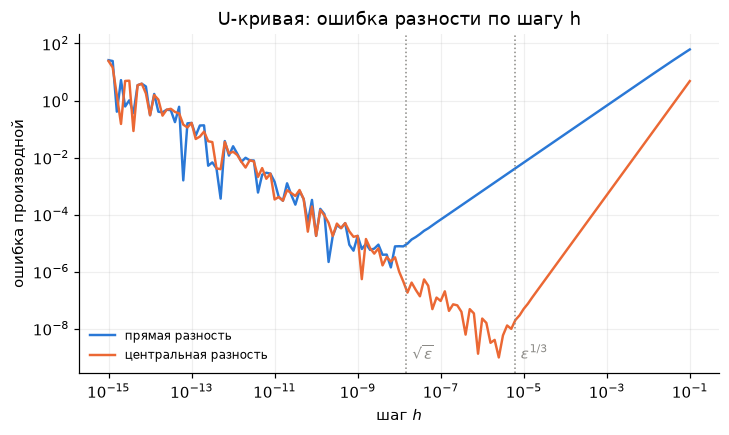

In [2]:
exact = rosen_grad(X0_ROSEN)[0]
ef, ec = ucurve(rosen, X0_ROSEN, 0, exact)                           # ошибки по сетке HS
slope = lambda e, lo, hi: np.polyfit(np.log10(HS[(HS >= lo) & (HS <= hi)]), np.log10(e[(HS >= lo) & (HS <= hi)]), 1)[0]
for name, e, lo in (("прямая", ef, 1e-5), ("центральная", ec, 1e-4)):
    j = np.argmin(e)
    print(f"{name:12s}: лучший h = {HS[j]:.1e}, ошибка {e[j]:.1e};  наклон справа {slope(e, lo, 1e-1):.2f}, слева {slope(e, 1e-15, 1e-10):.2f}")
f11 = 2 - 400 * X0_ROSEN[1] + 1200 * X0_ROSEN[0] ** 2                 # d^2 f / d x1^2 в старте
print(f"формула: h* = 2 sqrt(eps |f| / |f''|) = {2 * np.sqrt(EPS * rosen(X0_ROSEN) / f11):.1e}, ошибка ~ {2 * np.sqrt(EPS * rosen(X0_ROSEN) * f11):.1e}   (в конспекте: 4e-9 и до 5e-6)")
fig, ax = plt.subplots(figsize=(7.5, 4))
ucurve_plot(ax, [ef, ec], ["прямая разность", "центральная разность"], [BLUE, ORANGE])
ax.set(title="U-кривая: ошибка разности по шагу h"); plt.show()

**SciPy без `jac`.** BFGS на Розенброке с точным градиентом и с разностным, который SciPy берёт сам (`jac=None`, прямые разности с шагом `eps = 1.49e-8`): итераций $33$ и $33$, вызовов $f$ — $40$ и $120$, а точный градиент в найденной точке — $10^{-8}$ против $10^{-5}$.

In [3]:
for name, jac in (("точный градиент", rosen_grad), ("jac=None (разности)", None), ("jac='3-point'", "3-point")):
    r = minimize(rosen, X0_ROSEN, jac=jac, method="BFGS", options={"gtol": 1e-6})
    print(f"{name:20s}: итераций {r.nit}, вызовов f {r.nfev:3d}, |grad f(x*)| точный = {np.linalg.norm(rosen_grad(r.x)):.1e}, |x* - (1,1)| = {np.linalg.norm(r.x - 1):.1e}")

точный градиент     : итераций 33, вызовов f  40, |grad f(x*)| точный = 2.6e-08, |x* - (1,1)| = 1.7e-09
jac=None (разности) : итераций 33, вызовов f 120, |grad f(x*)| точный = 6.1e-06, |x* - (1,1)| = 1.0e-05
jac='3-point'       : итераций 33, вызовов f 200, |grad f(x*)| точный = 1.6e-08, |x* - (1,1)| = 1.4e-08


## 3. Алгоритмическое дифференцирование вперёд

**Главная мысль.** Программа, вычисляющая $f$, — цепочка элементарных операций: $+$, $\times$, $\sin$, $\exp$, $\sqrt{\ }$, у каждой производная известна. Если применять правило цепочки операция за операцией, получается производная **точная** — без $h$, с ошибкой только от округления самих операций, $\sim10^{-16}$. Это *алгоритмическое дифференцирование* (АД): не символьное (формула не выписывается и не растёт) и не численное (нет $h$).

### 3.1. Программа как список операций

Возьмём $f(x_1,x_2)=x_1x_2+\sin(x_1x_2)$. Компьютер считает её в три шага, и у $v_1$ два потребителя:

$$
v_1=x_1x_2,\qquad v_2=\sin v_1,\qquad f=v_1+v_2 .
$$

Промежуточные величины $v_i$ — вершины **графа вычислений**; стрелка $v_j\to v_i$ означает «$v_i$ вычислена из $v_j$». В точке $(2,\,0.5)$: $v_1=1$, $v_2=\sin1=0.8415$, $f=1.8415$.

### 3.2. Прямой режим: вместе с каждым $v_i$ несём $\dot v_i$

Выберем направление $d\in\mathbb R^n$ и будем вместе с каждой величиной $v_i$ считать её производную по направлению — число $\dot v_i=\nabla v_i^\top d$ («$v$ с точкой»). Для входов $\dot x=d$; для каждой операции $v_i=\varphi_i(\text{аргументы})$ по правилу цепочки

$$
\dot v_i=\sum_{j:\ v_j\to v_i}\frac{\partial\varphi_i}{\partial v_j}\,\dot v_j ,
$$

и все $\dot v_j$ справа уже известны — они посчитаны раньше, в том же порядке, что и $v_j$.

**Алгоритм (прямой режим).** Дано $x\in\mathbb R^n$ и направление $d\in\mathbb R^n$.

1. $\dot x_j=d_j$ для всех входов.
2. Для операций $i=1,2,\dots$ по порядку программы: вычислить $v_i$ и тут же $\dot v_i$ по формуле выше.
3. На выходе $\dot f=\nabla f(x)^\top d$ — производная по направлению $d$.

**Трасса** для $d=(1,0)$, то есть $\dot x_1=1$, $\dot x_2=0$:

1. $v_1=x_1x_2=1$; $\dot v_1=\dot x_1x_2+x_1\dot x_2=0.5$.
2. $v_2=\sin v_1=0.8415$; $\dot v_2=\cos v_1\cdot\dot v_1=0.5403\cdot0.5=0.2702$.
3. $f=v_1+v_2=1.8415$; $\dot f=\dot v_1+\dot v_2=0.7702$.

Это $\partial f/\partial x_1$: проверка руками — $\partial_1f=x_2(1+\cos x_1x_2)=0.5\cdot1.5403=0.7702$. Для $\partial f/\partial x_2$ нужен второй проход с $d=(0,1)$.

<img src="img/04_graph_forward.png" width="900" alt="граф вычислений f = x₁x₂ + sin(x₁x₂) в точке (2, 0.5): вершины x₁ = 2, x₂ = 0.5, v₁ = 1, v₂ = 0.8415, f = 1.8415; под каждой вершиной её производная по направлению d = (1, 0): ẋ₁ = 1, ẋ₂ = 0, v̇₁ = 0.5, v̇₂ = 0.2702, ḟ = 0.7702; на стрёлках локальные производные x₂ = 0.5, x₁ = 2, cos v₁ = 0.5403, 1, 1">

*Прямой режим: значения $v_i$ (сверху) и их производные по направлению $\dot v_i$ (снизу) текут по стрелкам слева направо; на каждой стрелке — локальная производная операции. $\dot f$ собирается из $\dot v_1$ по двум путям: напрямую и через $\sin$.*

### 3.3. Цена

На каждую операцию программы прямой режим добавляет одну-две: $\dot v_i$ — это столько же умножений, сколько аргументов у операции. Оценка Гриванка (Griewank & Walther, 2008): одно направление стоит **не больше $2.5$ вычислений $f$**, при любой программе. Но направление — одно; весь градиент из $n$ компонент требует $n$ проходов, как и разности, — зато точных. Якобиан $m\times n$ — тоже $n$ проходов, по столбцу за проход.

**Реальный кейс.** Произведение якобиана на вектор $J(x)\,d$ без самого якобиана — ровно один прямой проход: CasADi `jtimes(f, x, d)`, JAX `jvp`; Julia `ForwardDiff` реализует прямой режим *дуальными числами* — к каждому числу приписана его «точка».

## 4. Обратный режим: весь градиент за один проход

**Главная мысль.** Если пройти по графу в обратную сторону — от $f$ к входам — и нести *сопряжённые* величины $\bar v_i=\partial f/\partial v_i$ («$v$ с чертой»: насколько $f$ чувствительна к $v_i$), то за **один** обратный проход получаются все $n$ компонент градиента: $\bar x_j=\partial f/\partial x_j$. Цена — не больше $4$ вычислений $f$ при любом $n$; это *принцип дешёвого градиента* (Griewank). Плата — память: все $v_i$ прямого прохода нужно хранить.

### 4.1. Тот же пример назад

Начинаем с $\bar f=1$ и идём по операциям в обратном порядке; каждая операция $v_i=\varphi_i(\dots,v_j,\dots)$ передаёт своим аргументам долю чувствительности $\bar v_j\mathrel{+}=\bar v_i\,\partial\varphi_i/\partial v_j$. Там, где у величины два потребителя, доли складываются.

1. $f=v_1+v_2$: $\bar v_1\mathrel{+}=\bar f\cdot1=1$, $\bar v_2\mathrel{+}=\bar f\cdot1=1$.
2. $v_2=\sin v_1$: $\bar v_1\mathrel{+}=\bar v_2\cos v_1=0.5403$ — теперь $\bar v_1=1.5403$: обе дороги из $v_1$ в $f$ учтены.
3. $v_1=x_1x_2$: $\bar x_1=\bar v_1x_2=0.7702$, $\bar x_2=\bar v_1x_1=3.0806$.

$\nabla f(2,0.5)=(0.7702,\ 3.0806)$ — проверьте по формуле $\nabla f=(x_2(1+\cos x_1x_2),\ x_1(1+\cos x_1x_2))$. Один проход — обе компоненты.

<img src="img/05_graph_reverse.png" width="900" alt="тот же граф вычислений, стрелки развёрнуты от f к входам; у вершин сопряжённые величины: f̄ = 1, v̄₂ = 1, v̄₁ = 1 + 0.5403 = 1.5403 (две доли складываются), x̄₁ = 0.7702, x̄₂ = 3.0806; на стрелках те же локальные производные; справа подпись: градиент (0.7702, 3.0806) за один проход">

*Обратный режим: те же локальные производные на стрелках, но чувствительность течёт от $f$ к входам. В $v_1$ сходятся две доли — $1$ напрямую и $0.5403$ через $\sin$. Внизу графа — обе компоненты градиента.*

### 4.2. Алгоритм обратного режима и чем он отличается от прямого

1. **Прямой проход:** вычислить все $v_i$ по порядку и **запомнить** их — локальные производные ($\cos v_1$, $x_2$, $x_1$) нужны на обратном пути.
2. $\bar f=1$, все остальные $\bar v_i=0$, $\bar x_j=0$.
3. Для операций в **обратном** порядке, $i=N,\dots,1$: для каждого аргумента $v_j$ операции $v_i$ прибавить $\bar v_j\mathrel{+}=\bar v_i\,\partial\varphi_i/\partial v_j$.
4. На выходе $\bar x=\nabla f(x)$.

| | Прямой режим | Обратный режим |
|---|---|---|
| что несём | $\dot v_i=\nabla v_i^\top d$, по направлению $d$ | $\bar v_i=\partial f/\partial v_i$, от выхода |
| один проход даёт | одну производную по направлению | весь градиент |
| память | как у $f$ | все $v_i$ прямого прохода |

Градиент за $4$ цены $f$ при $n=2000$ выглядит чудом, пока не заметить, где спрятана плата: граф вычислений хранится целиком. Для нейросети это гигабайты активаций; для цепи из $1000$ грузиков — $13$ тысяч чисел.

### 4.3. Вперёд или назад

| Нужно | Проходов | Выбор |
|---|---|---|
| градиент, $m=1$ | назад: $1$; вперёд: $n$ | назад |
| якобиан $m\times n$ | вперёд: $n$; назад: $m$ | меньшее из $n$, $m$ |
| $\nabla^2f\,d$ — гессиан на вектор | назад по прямому: $1$ | не строить гессиан |

Последняя строка — *forward-over-reverse*: продифференцировать прямым режимом программу обратного прохода. Так SciPy через `hessp` и IPOPT получают действие гессиана на вектор, не собирая матрицу $n\times n$. Полный гессиан — $n$ таких проходов, и на цепи он стоит $5.5$ цены $f$ только потому, что CasADi видит его разреженность (раздел 5).

<img src="img/06_cost.png" width="900" alt="слева: цена градиента упругой цепи в единицах стоимости функции против числа переменных n = 80, 400, 2000 в логарифмических осях — разности растут как n + 1 (81, 401, 2001), обратный режим CasADi держится на 1.6, гессиан на 5.5–5.7, гессиан на вектор на 3.3; справа: время одного градиента при n = 2000 — разности около 150 мс против CasADi около 0.2 мс">

*Слева — число операций на градиент и гессиан упругой цепи в единицах числа операций самой энергии: разности растут линейно с $n$, обратный режим — горизонталь $1.6$ при $n=80$, $400$ и $2000$. Справа — время одного градиента при $n=2000$: сотни миллисекунд против долей миллисекунды.*

**Реальный кейс.** Backpropagation в нейросетях — это обратный режим АД для $f=$ функция потерь, применённый к графу слоёв: PyTorch `loss.backward()` и есть шаг 3 алгоритма выше, а `requires_grad` — команда «запоминай $v_i$». У GPT-3 $175$ миллиардов параметров; обучение возможно потому, что обратный проход стоит около двух прямых, а не $1.75\cdot10^{11}$. IPOPT получает от CasADi градиент и гессиан лагранжиана тем же механизмом.

**Мини-задание (2 минуты).** Для $f=x_1x_2+\sin(x_1x_2)$ в точке $(1,\,\pi)$ пройдите обратный режим руками: чему равны $\bar v_1$ и $\nabla f$? *(Ответ — в разборе упражнения 7.3.)*

### Демо (b). Алгоритмическое дифференцирование своими руками (разделы 3–4)

**Что проверяем.** Программа $f=x_1x_2+\sin(x_1x_2)$ — три операции в списке `PROGRAM`. Прямой режим по направлению $d=(1,0)$ в точке $(2,0.5)$: $\dot v_1=0.5$, $\dot v_2=0.2702$, $\dot f=0.7702$. Обратный режим: $\bar v_2=1$, $\bar v_1=1.5403$, $\bar x=(0.7702,\ 3.0806)$ — весь градиент за один проход. Код `forward_mode` и `reverse_mode` — в ячейке настройки, по 10 строк каждый.

In [4]:
x = {"x1": 2.0, "x2": 0.5}
val, dot = forward_mode(PROGRAM, x, {"x1": 1.0, "x2": 0.0})            # прямой режим, d = (1, 0)
print("прямой режим, d = (1, 0):", {k: round(v, 4) for k, v in dot.items()})
val, bar = reverse_mode(PROGRAM, x)                                    # обратный режим
print("обратный режим:          ", {k: round(v, 4) for k, v in bar.items()})
g = lambda x1, x2: np.array([x2 * (1 + np.cos(x1 * x2)), x1 * (1 + np.cos(x1 * x2))])
print("градиент по формуле:     ", g(2.0, 0.5).round(4), "  (в конспекте: 0.7702, 3.0806)")
assert np.allclose([bar["x1"], bar["x2"]], g(2.0, 0.5)) and np.isclose(dot["f"], g(2.0, 0.5)[0])

прямой режим, d = (1, 0): {'x1': 1.0, 'x2': 0.0, 'v1': 0.5, 'v2': np.float64(0.2702), 'f': np.float64(0.7702)}
обратный режим:           {'x1': np.float64(0.7702), 'x2': np.float64(3.0806), 'v1': np.float64(1.5403), 'v2': 1.0, 'f': 1.0}
градиент по формуле:      [0.7702 3.0806]   (в конспекте: 0.7702, 3.0806)


**Трасса обратного прохода по шагам** — та же, что в §4.1: $f=v_1+v_2$ раздаёт по единице, $v_2=\sin v_1$ добавляет $v_1$ долю $\cos v_1=0.5403$, $v_1=x_1x_2$ раздаёт входам $\bar v_1x_2$ и $\bar v_1x_1$.

In [5]:
val = dict(x)
for name, op, args in PROGRAM:
    val[name] = OPS[op][0](*[val[k] for k in args])
bar = {k: 0.0 for k in val}; bar["f"] = 1.0
for name, op, args in reversed(PROGRAM):
    a = [val[k] for k in args]
    for p, k in zip(OPS[op][1](*a), args):
        bar[k] += bar[name] * p
        print(f"{name} = {op}{args}: {k} += {bar[name]:.4f} * {p:.4f}  ->  bar {k} = {bar[k]:.4f}")

f = add('v1', 'v2'): v1 += 1.0000 * 1.0000  ->  bar v1 = 1.0000
f = add('v1', 'v2'): v2 += 1.0000 * 1.0000  ->  bar v2 = 1.0000
v2 = sin('v1',): v1 += 1.0000 * 0.5403  ->  bar v1 = 1.5403
v1 = mul('x1', 'x2'): x1 += 1.5403 * 0.5000  ->  bar x1 = 0.7702
v1 = mul('x1', 'x2'): x2 += 1.5403 * 2.0000  ->  bar x2 = 3.0806


**Мини-задание лекции:** та же функция в $(1,\pi)$. $v_1=\pi$, $\bar v_1=1+\cos\pi=0$ — градиент нулевой, точка стационарная.

In [6]:
val, bar = reverse_mode(PROGRAM, {"x1": 1.0, "x2": np.pi})
print(f"в (1, pi): v1 = {val['v1']:.4f}, bar v1 = {bar['v1']:.1e}, градиент = ({bar['x1']:.1e}, {bar['x2']:.1e})")

в (1, pi): v1 = 3.1416, bar v1 = 0.0e+00, градиент = (0.0e+00, 0.0e+00)


## 5. CasADi: граф операций и разреженность

**Главная мысль.** CasADi не вычисляет функцию, а **записывает её граф операций**, когда вы пишете выражение от символьной переменной (`SX.sym`), и применяет к графу оба режима АД: `gradient` — обратный, `jtimes` — прямой, `hessian` — один по другому. Разреженность производных он находит по самому графу, без вычислений.

На семинарах 4 и 6 вы это уже вызывали; теперь понятно, что внутри. Энергия упругой цепи из ДЗ 4 — цикл по пружинам в пять строк:

```python
v = ca.SX.sym("v", 2 * N)                              # (y_1..y_N, z_1..z_N)
y = ca.vertcat(-2.0, v[:N], 2.0); z = ca.vertcat(1.0, v[N:], 1.0)
E = 0
for j in range(N + 1):                                 # пружина j между грузиками j и j+1
    d = ca.sqrt((y[j+1] - y[j])**2 + (z[j+1] - z[j])**2)
    E += 0.5 * D * (d - L)**2
E += m * g * ca.sum1(z[1:-1])
G = ca.Function("G", [v], [ca.gradient(E, v)])           # обратный режим — за одну строку
H = ca.Function("H", [v], [ca.hessian(E, v)[0]])
```

`Function` компилирует граф в список операций, и у него есть счётчик `n_instructions()` — число операций, честная мера цены:

| $N$ грузиков ($n=2N$) | операций в $E$ | в $\nabla E$ | в $\nabla^2E$ | ненулевых в $\nabla^2E$ |
|---|---|---|---|---|
| $40$ | $537$ | $860$ ($\times1.6$) | $2968$ ($\times5.5$) | $472$ из $6400$ — $7\,\%$ |
| $200$ | $2617$ | $4220$ ($\times1.6$) | $14\,836$ ($\times5.7$) | $1.5\,\%$ |
| $1000$ | $13\,017$ | $21\,020$ ($\times1.6$) | $74\,168$ ($\times5.7$) | $0.3\,\%$ |

Градиент CasADi совпадает с градиентом, выписанным руками, с точностью $9\cdot10^{-16}$; разностный ошибается на $10^{-6}$.

<img src="img/07_sparsity.png" width="900" alt="слева: портрет ненулевых элементов гессиана упругой цепи 80×80 из CasADi — четыре трёхдиагональные ленты (блоки y–y, z–z и две перекрёстные y–z), 472 ненулевых из 6400; справа: тот же гессиан в равновесии цепи, собранный разностями по значениям энергии, в цвете по модулю элемента — ленты видны, но весь квадрат покрыт шумом до 3e−5, и «ненулевых» 3996">

*Слева — гессиан энергии цепи $80\times80$ из CasADi: каждая пружина связывает двух соседей, отсюда четыре трёхдиагональные ленты и $7\,\%$ ненулевых; CasADi знает это заранее и считает только их. Справа — тот же гессиан разностями по энергии ($25\,600$ вычислений): ленты видны, но между ними шум до $3\cdot10^{-5}$, и из $5928$ нулей точного гессиана $3524$ стали «ненулевыми».*

**Чего CasADi не делает.**

- Не дифференцирует код с ветвлением по данным: `if x > 0` в Python выполнится один раз при построении графа; нужен `ca.if_else`.
- Не понимает `numpy` внутри выражения: `np.sin(x)` от символьного `x` — ошибка; нужен `ca.sin`.
- Граф растёт с числом операций: цепь из $1000$ грузиков — $13$ тысяч операций и доли секунды на построение, миллион операций — минуты и гигабайты; для таких задач есть `MX` — граф из матричных операций и вызовов функций, а не из скаляров.

**Реальный кейс.** CasADi — слой производных в acados и `do-mpc` (MPC в реальном времени) и в задачах оптимального управления лекции 15. Что даёт точный гессиан солверу: IPOPT на упругой цепи из прямой — $24$ итерации с `hessian_approximation = "exact"` (гессиан от CasADi) против $232$ с `"limited-memory"` (L-BFGS внутри IPOPT) — тот же ответ $E^\ast=-44.5388$, но в десять раз дольше.

### Демо (c). CasADi на упругой цепи (раздел 5)

**Что проверяем.** Энергия цепи как граф CasADi (цикл по пружинам, `chain_casadi`). Число операций `n_instructions()`: градиент $\times1.6$, гессиан $\times5.5$–$5.7$, гессиан на вектор через `jtimes` $\times3.3$ — при $N=40$, $200$, $1000$; ненулевых в гессиане $472$ из $6400$ при $N=40$. IPOPT из прямой: $24$ итерации с точным гессианом против $232$ с L-BFGS.

In [7]:
print(f"{'N':>5s} {'n':>5s} {'E':>7s} {'grad':>7s} {'hess':>7s} {'H d':>7s}   ненулевых в гессиане")
for N in (40, 200, 1000):
    nf, ng, nh, nhd, nnz = chain_costs(N)
    print(f"{N:5d} {2 * N:5d} {nf:7d} {ng:7d} {nh:7d} {nhd:7d}   {nnz} из {(2 * N) ** 2} = {100 * nnz / (2 * N) ** 2:.1f} %   (x{ng / nf:.2f}, x{nh / nf:.1f}, x{nhd / nf:.1f})")
print("в конспекте: x1.6, x5.5-5.7, x3.3; 472 из 6400")

    N     n       E    grad    hess     H d   ненулевых в гессиане
   40    80     537     860    2968    1759   472 из 6400 = 7.4 %   (x1.60, x5.5, x3.3)
  200   400    2617    4220   14836    8639   2392 из 160000 = 1.5 %   (x1.61, x5.7, x3.3)


 1000  2000   13017   21020   74168   43039   11992 из 4000000 = 0.3 %   (x1.61, x5.7, x3.3)
в конспекте: x1.6, x5.5-5.7, x3.3; 472 из 6400


**Портрет гессиана.** Пружина связывает двух соседей, отсюда четыре трёхдиагональные ленты (блоки $y$–$y$, $y$–$z$, $z$–$y$, $z$–$z$). CasADi находит эти ленты по графу до всяких вычислений.

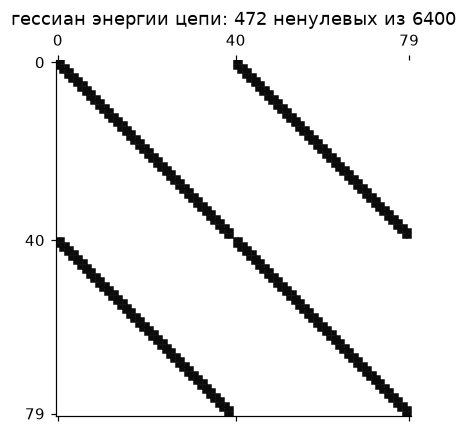

In [8]:
pattern, v_star, Hfun = chain_pattern(40)                            # структура из графа и равновесие цепи
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.spy(pattern, markersize=2.5, color=INK); ax.grid(False)
ax.set(title=f"гессиан энергии цепи: {int(pattern.sum())} ненулевых из 6400", xticks=[0, 40, 79], yticks=[0, 40, 79]); plt.show()

**Что даёт солверу точный гессиан.** IPOPT на той же цепи из прямой: `hessian_approximation="exact"` — гессиан от CasADi, `"limited-memory"` — L-BFGS внутри IPOPT.

In [9]:
v, E = chain_casadi(40); v0 = make_elastic_chain(40)[2]                     # старт — прямая между концами
for mode in ("exact", "limited-memory"):
    solver = ca.nlpsol("s", "ipopt", {"x": v, "f": E}, {"ipopt.hessian_approximation": mode, "ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes", "ipopt.tol": 1e-8})
    sol = solver(x0=v0); st = solver.stats()
    print(f"hessian_approximation = {mode:15s}: итераций {st['iter_count']:3d}, E* = {float(sol['f']):.4f}, {st['return_status']}")
print("в конспекте: 24 против 232")

hessian_approximation = exact          : итераций  24, E* = -44.5388, Solve_Succeeded


hessian_approximation = limited-memory : итераций 232, E* = -44.5388, Solve_Succeeded
в конспекте: 24 против 232


## 6. Что это даёт численно

Что передавать `scipy.optimize.minimize`:

| Аргумент | Что это | Когда |
|---|---|---|
| `jac=None` | прямые разности, шаг $1.49\cdot10^{-8}$ | $f$ дёшева, $n\le100$, точность $10^{-5}$ устраивает |
| `jac=grad` | ваш градиент: руками или `ca.Function` | всегда, когда он есть |
| `hess=hess` или `hessp=` | гессиан или его действие на вектор | Ньютон (`trust-exact`, `Newton-CG`); `hessp` — когда $n$ велико |

Три правила на практике:

1. **Проверяйте градиент разностями** один раз, центральной разностью с $h\approx10^{-6}$: относительное расхождение больше $10^{-5}$ — ошибка в формуле, не в разности. ДЗ 4 так проверяет гессиан; IPOPT — `derivative_test`.
2. **Разности от шумной $f$** — не градиент, а шум: $f$ с точностью $10^{-10}$ даёт градиент с точностью $10^{-5}$ в лучшем случае (§2.4).
3. **Если $f$ — ваша программа, отдайте её АД:** CasADi для задач с матрицами и солверами, PyTorch или JAX — для нейросетей. Производная будет точной, а цена градиента — три-четыре вычисления функции при любом $n$.

## 7. Итоги лекции

1. У конечной разности две ошибки — усечения $\sim h$ и округления $\sim\varepsilon/h$; лучший шаг $h\sim\sqrt\varepsilon\approx10^{-8}$, лучшая точность $\sim10^{-8}$; центральная разность — $h\sim\varepsilon^{1/3}$, точность $\sim10^{-11}$, вдвое дороже (§2).
2. Градиент разностями стоит $n$ вычислений $f$, гессиан — $n^2$ и четыре знака; SciPy без `jac` делает именно это (§2.3–2.4).
3. Программа — список элементарных операций; прямой режим АД несёт $\dot v_i$ и даёт точную производную по направлению за $\le2.5$ цены $f$ (§3).
4. Обратный режим несёт $\bar v_i=\partial f/\partial v_i$ от выхода к входам и даёт весь градиент за один проход, $\le4$ цены $f$ при любом $n$; плата — память; backpropagation — это он (§4).
5. CasADi записывает граф операций, применяет оба режима и находит разреженность: градиент цепи за $1.6$ цены энергии, гессиан за $5.5$; точный гессиан экономит IPOPT десять раз по итерациям (§5).

## 8. Что дальше

**Лекция 8** (28.10) — ограничения-равенства: множители Лагранжа, LICQ, условия второго порядка — часть III. **Лекция 9** — алгоритмы для равенств: Ньютон–Лагранж и обобщённый Гаусс–Ньютон; якобианы ограничений в них — из CasADi.

**ДЗ 4** выдано сегодня, срок 4 ноября ([карточка](../../homeworks/hw04.md)): линейный поиск и доверительная область из лекции 6 и задача 3 — U-кривая и градиент CasADi из этой лекции.

**Литература к лекции.**
- Diehl, *Lecture Notes on Numerical Optimization*, глава *Calculating Derivatives*: конечные разности, прямой и обратный режим АД, цена.
- Nocedal & Wright, гл. 8: §8.1 — конечные разности и выбор шага, §8.2 — алгоритмическое дифференцирование, прямой и обратный режимы.
- Griewank & Walther, *Evaluating Derivatives* (2008) — принцип дешёвого градиента и оценки $2.5$ и $4$.
- Документация CasADi, раздел *Derivatives*: `jacobian`, `gradient`, `hessian`, `jtimes`, разреженность.

## 9. Упражнения

Разбор с проверкой кодом — [`exercises07.ipynb`](exercises07.ipynb), краткие ответы — [`exercises07.md`](exercises07.md). Все задачи домашние.

**7.0. Разминка — счёт руками.** Три пункта по минуте. *Суть: две ошибки и счёт проходов — на бумаге.*

- (а) $f(x)=e^x$ в $x=0$, прямая разность. Оцените ошибку при $h=10^{-4}$ и при $h=10^{-12}$ по формулам §2.1 — и скажите, какая из двух ошибок главная в каждом случае.
- (б) Якобиан $3\times1000$: сколько проходов нужно прямому режиму, сколько обратному? А для якобиана $1000\times3$?
- (в) Сколько проходов «назад по прямому» нужно на полный гессиан $n\times n$ без учёта разреженности?

**7.1. U-кривая своими руками** (с кодом). *Суть: наклоны веток — это показатели степени $h$ и $1/h$.*

- (а) Постройте U-кривые прямой и центральной разности для $\sin x$ в $x=1$, $h$ от $10^{-15}$ до $10^{-1}$. Найдите лучшие $h$ и ошибки; оцените наклоны веток в логарифмических осях.
- (б) Повторите для квадратичной $3x^2+x$ в $x=1$ с центральной разностью. Почему у U-кривой осталась одна ветка?

**7.2. Прямой режим руками.** *Суть: $\dot v$ течёт вместе с $v$.*

$f(x_1,x_2)=e^{x_1}x_2+x_1^2$ в точке $(0,1)$. Запишите программу из четырёх операций ($v_1=e^{x_1}$, $v_2=v_1x_2$, $v_3=x_1^2$, $f=v_2+v_3$) и выполните прямой режим по направлению $d=(1,1)$: все $\dot v_i$ и $\dot f$. Проверьте по формуле $\nabla f^\top d$.

**7.3. Обратный режим руками** (с кодом). *Суть: доли чувствительности складываются там, где у величины два потребителя.*

- (а) Та же функция и точка, что в 7.2: выполните обратный проход, получите $\bar x_1$, $\bar x_2$ и сверьте с $\nabla f$.
- (б) Мини-задание лекции: $f=x_1x_2+\sin(x_1x_2)$ в $(1,\pi)$ — $\bar v_1$ и $\nabla f$. Проверьте обе функции через `ca.gradient`.

**7.4. Мнимый трюк** (для желающих). *Суть: вычитания нет — нет и ошибки округления.*

Для вещественно-аналитической $f$ верно $f(x+ih)=f(x)+ihf'(x)-\tfrac{h^2}{2}f''(x)-\dots$, откуда $f'(x)\approx\operatorname{Im}f(x+ih)/h$ с ошибкой усечения $\sim h^2$ и **без вычитания**. Проверьте на Розенброке в $(-1.2,1)$ при $h=10^{-20}$ (ожидается ошибка $\sim10^{-14}$ при производной $-215.6$). Почему трюк не работает для $\lvert x\rvert$ и для функций с `if x > 0`?

**7.5. Разреженность и гессиан на вектор** (с кодом). *Суть: гессиан цепи — ленты, и CasADi это знает.*

Для упругой цепи с $N=10,\ 40,\ 160$ грузиками постройте через CasADi энергию, гессиан и произведение $\nabla^2E\,d$ как `jtimes(gradient(E, v), v, d)`. Для каждого $N$ выпишите `n_instructions()` энергии, гессиана и произведения и долю ненулевых элементов гессиана. Почему доля падает с $N$, а цена произведения на вектор остаётся $\approx3.3$ цены $E$?

## Вопросы для самопроверки

1. Почему ошибка прямой разности не может быть меньше $\sim\sqrt\varepsilon$, какой бы $h$ вы ни взяли?
2. Чем центральная разность точнее прямой и чем за это платят?
3. Что такое $\dot v_i$ и что такое $\bar v_i$; какой из них считается вместе с $v_i$, а какой — после?
4. Почему обратный режим даёт весь градиент за один проход, а прямой — нет?
5. Где спрятана плата за дешёвый градиент?
6. Что сделает CasADi со строкой `if x > 0:` внутри функции от `SX.sym`?